In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# OS1 — ANALYSE EXPLORATOIRE DAiSEE
# ============================================

# Charger les 3 datasets
train = pd.read_csv('../data/DAiSEE/Labels/TrainLabels.csv')
test = pd.read_csv('../data/DAiSEE/Labels/TestLabels.csv')
val = pd.read_csv('../data/DAiSEE/Labels/ValidationLabels.csv')

# Informations générales
print("=== INFORMATIONS GÉNÉRALES ===")
print(f"Train : {len(train)} clips")
print(f"Validation : {len(val)} clips")
print(f"Test : {len(test)} clips")
print(f"Total : {len(train)+len(val)+len(test)} clips")
print("\n=== APERÇU TRAIN ===")
print(train.head())
print("\n=== STATISTIQUES ===")
print(train.describe())

=== INFORMATIONS GÉNÉRALES ===
Train : 5358 clips
Validation : 1429 clips
Test : 1784 clips
Total : 8571 clips

=== APERÇU TRAIN ===
           ClipID  Boredom  Engagement  Confusion  Frustration 
0  1100011002.avi        0           2          0             0
1  1100011003.avi        0           2          0             0
2  1100011004.avi        0           3          0             0
3  1100011005.avi        0           3          0             0
4  1100011006.avi        0           3          0             0

=== STATISTIQUES ===
           Boredom   Engagement    Confusion  Frustration 
count  5358.000000  5358.000000  5358.000000   5358.000000
mean      0.804405     2.413027     0.430198      0.270997
std       0.855973     0.600070     0.692825      0.563085
min       0.000000     0.000000     0.000000      0.000000
25%       0.000000     2.000000     0.000000      0.000000
50%       1.000000     2.000000     0.000000      0.000000
75%       1.000000     3.000000     1.000000    

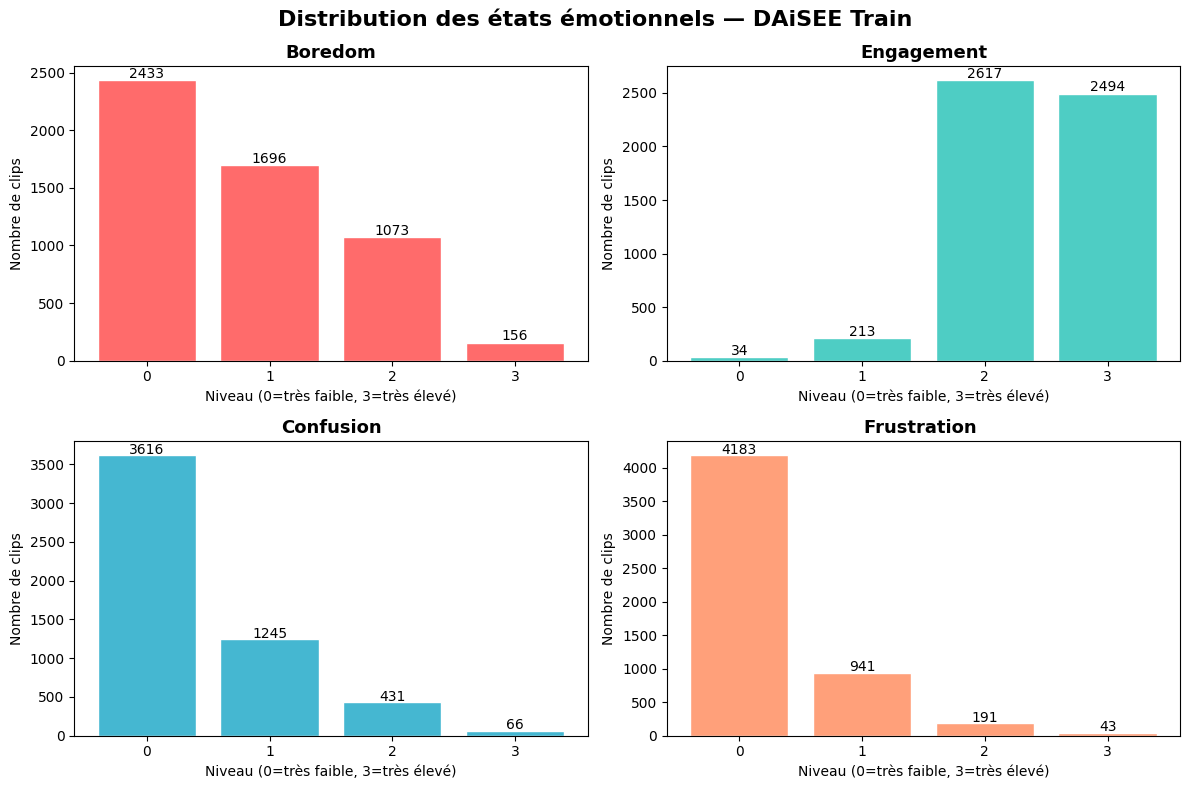

Graphique sauvegardé !


In [2]:
# ============================================
# VISUALISATION — DISTRIBUTIONS DES 4 ÉTATS
# ============================================

etats = ['Boredom', 'Engagement', 'Confusion', 'Frustration ']
couleurs = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Distribution des états émotionnels — DAiSEE Train', 
             fontsize=16, fontweight='bold')

for i, (etat, couleur) in enumerate(zip(etats, couleurs)):
    ax = axes[i//2, i%2]
    counts = train[etat].value_counts().sort_index()
    bars = ax.bar(counts.index, counts.values, color=couleur, edgecolor='white')
    ax.set_title(f'{etat}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Niveau (0=très faible, 3=très élevé)')
    ax.set_ylabel('Nombre de clips')
    ax.set_xticks([0, 1, 2, 3])
    
    # Afficher les valeurs sur les barres
    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                str(count), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('../data/distribution_etats.png', dpi=150)
plt.show()
print("Graphique sauvegardé !")

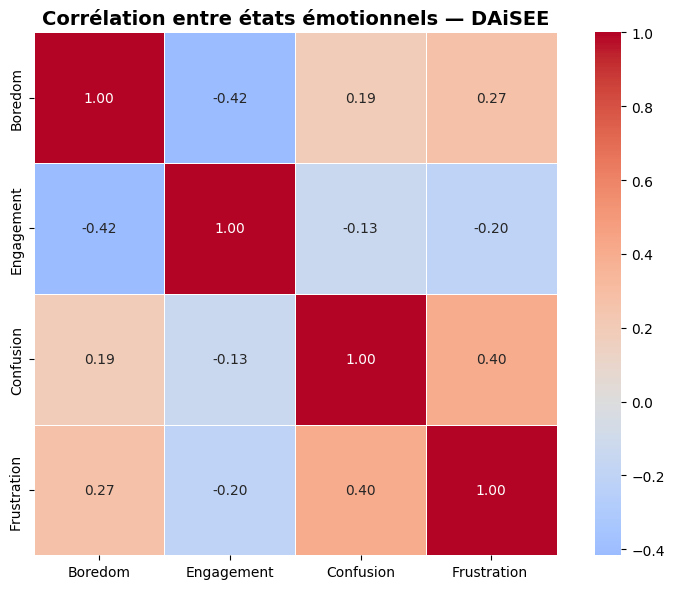

Matrice de corrélation sauvegardée !


In [3]:
# ============================================
# MATRICE DE CORRÉLATION ENTRE LES 4 ÉTATS
# ============================================

fig, ax = plt.subplots(figsize=(8, 6))

corr = train[etats].corr()

sns.heatmap(corr, 
            annot=True, 
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            ax=ax,
            linewidths=0.5,
            square=True)

ax.set_title('Corrélation entre états émotionnels — DAiSEE', 
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../data/correlation_etats.png', dpi=150)
plt.show()
print("Matrice de corrélation sauvegardée !")

In [4]:
print(train.columns.tolist())
print(train.columns.str.strip().tolist())


['ClipID', 'Boredom', 'Engagement', 'Confusion', 'Frustration ']
['ClipID', 'Boredom', 'Engagement', 'Confusion', 'Frustration']


In [5]:
# Corriger les noms de colonnes
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()
val.columns = val.columns.str.strip()

# Vérifier la correction
print(train.columns.tolist())

['ClipID', 'Boredom', 'Engagement', 'Confusion', 'Frustration']


KeyError: "['Frustration '] not in index"

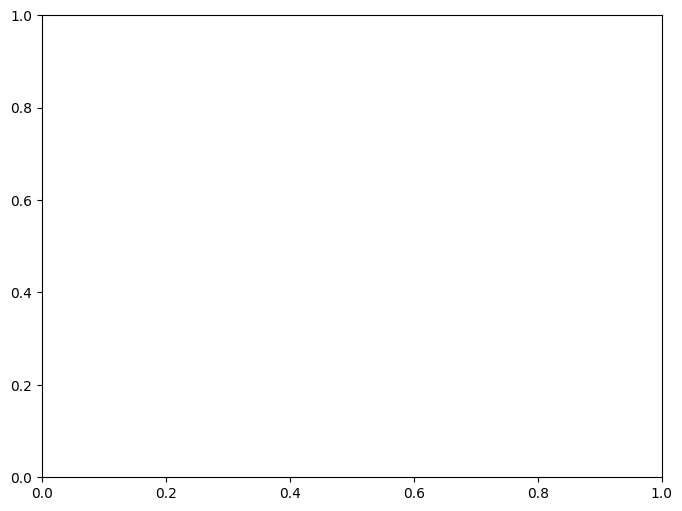

In [6]:
# ============================================
# MATRICE DE CORRÉLATION ENTRE LES 4 ÉTATS
# ============================================

fig, ax = plt.subplots(figsize=(8, 6))

corr = train[etats].corr()

sns.heatmap(corr, 
            annot=True, 
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            ax=ax,
            linewidths=0.5,
            square=True)

ax.set_title('Corrélation entre états émotionnels — DAiSEE', 
             fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../data/correlation_etats.png', dpi=150)
plt.show()
print("Matrice de corrélation sauvegardée !")

In [ ]:
# Redéfinir etats avec les bons noms
etats = ['Boredom', 'Engagement', 'Confusion', 'Frustration']

# Vérifier
print(train[etats].head())

In [1]:
# ============================================
# IDENTIFICATION DES PATTERNS CRITIQUES
# ============================================

print("=== PATTERNS CRITIQUES ===\n")

# Pattern 1 : Confusion haute + Engagement faible
p1 = train[(train['Confusion'] >= 2) & (train['Engagement'] <= 1)]
print(f"Pattern 1 — Confusion haute + Engagement faible : {len(p1)} clips ({len(p1)/len(train)*100:.1f}%)")

# Pattern 2 : Frustration haute
p2 = train[train['Frustration'] >= 2]
print(f"Pattern 2 — Frustration élevée : {len(p2)} clips ({len(p2)/len(train)*100:.1f}%)")

# Pattern 3 : Ennui élevé
p3 = train[train['Boredom'] >= 2]
print(f"Pattern 3 — Ennui élevé : {len(p3)} clips ({len(p3)/len(train)*100:.1f}%)")

# Pattern 4 : Engagement nul
p4 = train[train['Engagement'] == 0]
print(f"Pattern 4 — Engagement nul : {len(p4)} clips ({len(p4)/len(train)*100:.1f}%)")

# Pattern 5 : Situation critique (confusion + frustration + faible engagement)
p5 = train[(train['Confusion'] >= 2) & 
           (train['Frustration'] >= 2) & 
           (train['Engagement'] <= 1)]
print(f"Pattern 5 — Situation critique totale : {len(p5)} clips ({len(p5)/len(train)*100:.1f}%)")

# Pattern 6 : Bon engagement
p6 = train[train['Engagement'] >= 2]
print(f"Pattern 6 — Bon engagement : {len(p6)} clips ({len(p6)/len(train)*100:.1f}%)")

print(f"\nTotal clips analysés : {len(train)}")

=== PATTERNS CRITIQUES ===



NameError: name 'train' is not defined

In [15]:
# ============================================
# SÉLECTION DES 50 SCÉNARIOS REPRÉSENTATIFS
# ============================================

import numpy as np

scenarios = []

# 1. Scénarios stables — Bon engagement (15 scénarios)
stable = train[train['Engagement'] >= 2].sample(15, random_state=42)
stable = stable.copy()
stable['pattern'] = 'stable'
scenarios.append(stable)

# 2. Scénarios ennui élevé (10 scénarios)
ennui = train[train['Boredom'] >= 2].sample(10, random_state=42)
ennui = ennui.copy()
ennui['pattern'] = 'ennui_eleve'
scenarios.append(ennui)

# 3. Scénarios frustration (8 scénarios)
frustration = train[train['Frustration'] >= 2].sample(8, random_state=42)
frustration = frustration.copy()
frustration['pattern'] = 'frustration'
scenarios.append(frustration)

# 4. Scénarios confusion (7 scénarios)
confusion = train[train['Confusion'] >= 2].sample(7, random_state=42)
confusion = confusion.copy()
confusion['pattern'] = 'confusion'
scenarios.append(confusion)

# 5. Scénarios engagement faible (6 scénarios)
eng_faible = train[train['Engagement'] <= 1].sample(6, random_state=42)
eng_faible = eng_faible.copy()
eng_faible['pattern'] = 'engagement_faible'
scenarios.append(eng_faible)

# 6. Scénarios critiques (4 scénarios)
critiques = train[(train['Confusion'] >= 2) & (train['Frustration'] >= 2)]
critiques = critiques.sample(min(4, len(critiques)), random_state=42)
critiques = critiques.copy()
critiques['pattern'] = 'critique'
scenarios.append(critiques)

# Combiner tous les scénarios
df_scenarios = pd.concat(scenarios, ignore_index=True)

print(f"Total scénarios sélectionnés : {len(df_scenarios)}")
print(f"\nRépartition par pattern :")
print(df_scenarios['pattern'].value_counts())

# Sauvegarder
df_scenarios.to_csv('../data/scenarios_50.csv', index=False)
print("\nScénarios sauvegardés dans data/scenarios_50.csv !")

Total scénarios sélectionnés : 50

Répartition par pattern :
pattern
stable               15
ennui_eleve          10
frustration           8
confusion             7
engagement_faible     6
critique              4
Name: count, dtype: int64

Scénarios sauvegardés dans data/scenarios_50.csv !


In [ ]:
# Dernière cellule — Résumé final OS1
print("=== RÉSUMÉ OS1 ===")
print(f"Dataset : {len(train)+len(val)+len(test)} clips total")
print(f"Pattern dominant : Bon engagement (95.4%)")
print(f"Pattern critique : Ennui élevé (22.9%)")
print(f"Scénarios créés : 50")
print(f"Fichier sauvegardé : data/scenarios_50.csv")
print("\nOS1 TERMINÉ ✓")

In [7]:
# ============================================
# TRANSITIONS CRITIQUES
# ============================================

print("=== TRANSITIONS CRITIQUES ===\n")

# Trier par ClipID pour avoir les séquences dans l'ordre
train_sorted = train.sort_values('ClipID').reset_index(drop=True)

# Détecter transition Engagement → Boredom
transitions_eb = []
for i in range(1, len(train_sorted)):
    prev = train_sorted.iloc[i-1]
    curr = train_sorted.iloc[i]
    # Engagement baisse ET Boredom augmente
    if prev['Engagement'] >= 2 and curr['Engagement'] <= 1 and curr['Boredom'] >= 2:
        transitions_eb.append({
            'clip_avant': prev['ClipID'],
            'clip_apres': curr['ClipID'],
            'engagement_avant': prev['Engagement'],
            'engagement_apres': curr['Engagement'],
            'boredom_apres': curr['Boredom']
        })

# Détecter transition Engagement → Confusion
transitions_ec = []
for i in range(1, len(train_sorted)):
    prev = train_sorted.iloc[i-1]
    curr = train_sorted.iloc[i]
    # Engagement baisse ET Confusion augmente
    if prev['Engagement'] >= 2 and curr['Engagement'] <= 1 and curr['Confusion'] >= 2:
        transitions_ec.append({
            'clip_avant': prev['ClipID'],
            'clip_apres': curr['ClipID'],
            'engagement_avant': prev['Engagement'],
            'engagement_apres': curr['Engagement'],
            'confusion_apres': curr['Confusion']
        })

print(f"Transitions Engagement → Boredom : {len(transitions_eb)} cas")
print(f"Transitions Engagement → Confusion : {len(transitions_ec)} cas")

# Afficher quelques exemples
print("\n--- Exemples Engagement → Boredom ---")
for t in transitions_eb[:3]:
    print(f"  {t['clip_avant']} → {t['clip_apres']} | Engagement {t['engagement_avant']}→{t['engagement_apres']} | Boredom={t['boredom_apres']}")

print("\n--- Exemples Engagement → Confusion ---")
for t in transitions_ec[:3]:
    print(f"  {t['clip_avant']} → {t['clip_apres']} | Engagement {t['engagement_avant']}→{t['engagement_apres']} | Confusion={t['confusion_apres']}")

=== TRANSITIONS CRITIQUES ===

Transitions Engagement → Boredom : 146 cas
Transitions Engagement → Confusion : 43 cas

--- Exemples Engagement → Boredom ---
  1100021050.avi → 1100021055.avi | Engagement 3→1 | Boredom=3
  1100022004.avi → 1100022005.avi | Engagement 3→1 | Boredom=2
  1100042020.avi → 1100042023.avi | Engagement 3→1 | Boredom=3

--- Exemples Engagement → Confusion ---
  1100051006.avi → 1100051007.avi | Engagement 2→1 | Confusion=2
  1100051014.avi → 1100051016.avi | Engagement 2→1 | Confusion=2
  1100062046.avi → 1100062049.avi | Engagement 2→1 | Confusion=2


In [8]:
# ============================================
# SEUILS D'ALERTE — CLIPS CONSÉCUTIFS
# ============================================

print("=== SEUILS D'ALERTE ===\n")

train_sorted = train.sort_values('ClipID').reset_index(drop=True)

# Détecter Boredom ≥ 2 pendant 3 clips consécutifs
alertes_boredom = []
compteur = 0

for i in range(len(train_sorted)):
    if train_sorted.iloc[i]['Boredom'] >= 2:
        compteur += 1
        if compteur >= 3:
            alertes_boredom.append({
                'clip': train_sorted.iloc[i]['ClipID'],
                'position': i,
                'boredom': train_sorted.iloc[i]['Boredom']
            })
    else:
        compteur = 0

# Détecter Confusion ≥ 2 pendant 2 clips consécutifs
alertes_confusion = []
compteur = 0

for i in range(len(train_sorted)):
    if train_sorted.iloc[i]['Confusion'] >= 2:
        compteur += 1
        if compteur >= 2:
            alertes_confusion.append({
                'clip': train_sorted.iloc[i]['ClipID'],
                'position': i,
                'confusion': train_sorted.iloc[i]['Confusion']
            })
    else:
        compteur = 0

# Détecter Frustration ≥ 2 pendant 2 clips consécutifs
alertes_frustration = []
compteur = 0

for i in range(len(train_sorted)):
    if train_sorted.iloc[i]['Frustration'] >= 2:
        compteur += 1
        if compteur >= 2:
            alertes_frustration.append({
                'clip': train_sorted.iloc[i]['ClipID'],
                'position': i,
                'frustration': train_sorted.iloc[i]['Frustration']
            })
    else:
        compteur = 0

print(f"Alertes Boredom ≥ 2 (3 clips consécutifs)    : {len(alertes_boredom)} cas")
print(f"Alertes Confusion ≥ 2 (2 clips consécutifs)  : {len(alertes_confusion)} cas")
print(f"Alertes Frustration ≥ 2 (2 clips consécutifs): {len(alertes_frustration)} cas")

print("\n--- Exemples alertes Boredom ---")
for a in alertes_boredom[:3]:
    print(f"  Clip : {a['clip']} | Boredom = {a['boredom']}")

=== SEUILS D'ALERTE ===

Alertes Boredom ≥ 2 (3 clips consécutifs)    : 270 cas
Alertes Confusion ≥ 2 (2 clips consécutifs)  : 102 cas
Alertes Frustration ≥ 2 (2 clips consécutifs): 32 cas

--- Exemples alertes Boredom ---
  Clip : 1100022002.avi | Boredom = 2
  Clip : 1100022003.avi | Boredom = 2
  Clip : 1100022004.avi | Boredom = 2


In [14]:
# ============================================
# SEGMENTATION 70/15/15 — Sans sklearn
# ============================================

import numpy as np

print("=== SEGMENTATION 70/15/15 ===\n")

# Combiner tous les données
all_data = pd.concat([train, val, test], ignore_index=True)
all_data = all_data.sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Total données : {len(all_data)} clips")

# Calculer les tailles
total = len(all_data)
taille_conception = int(total * 0.70)
taille_validation = int(total * 0.15)

# Segmenter
conception = all_data[:taille_conception]
validation = all_data[taille_conception:taille_conception + taille_validation]
test_final = all_data[taille_conception + taille_validation:]

print(f"Ensemble conception (70%)  : {len(conception)} clips")
print(f"Ensemble validation (15%)  : {len(validation)} clips")
print(f"Ensemble test (15%)        : {len(test_final)} clips")
print(f"Total vérifié              : {len(conception)+len(validation)+len(test_final)} clips")

# Sauvegarder
conception.to_csv('../data/DAiSEE/Labels/conception_70.csv', index=False)
validation.to_csv('../data/DAiSEE/Labels/validation_15.csv', index=False)
test_final.to_csv('../data/DAiSEE/Labels/test_15.csv', index=False)

print("\nSegmentation sauvegardée !")

=== SEGMENTATION 70/15/15 ===

Total données : 8571 clips
Ensemble conception (70%)  : 5999 clips
Ensemble validation (15%)  : 1285 clips
Ensemble test (15%)        : 1287 clips
Total vérifié              : 8571 clips

Segmentation sauvegardée !


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8744\1132577415.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_8744\1132577415.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


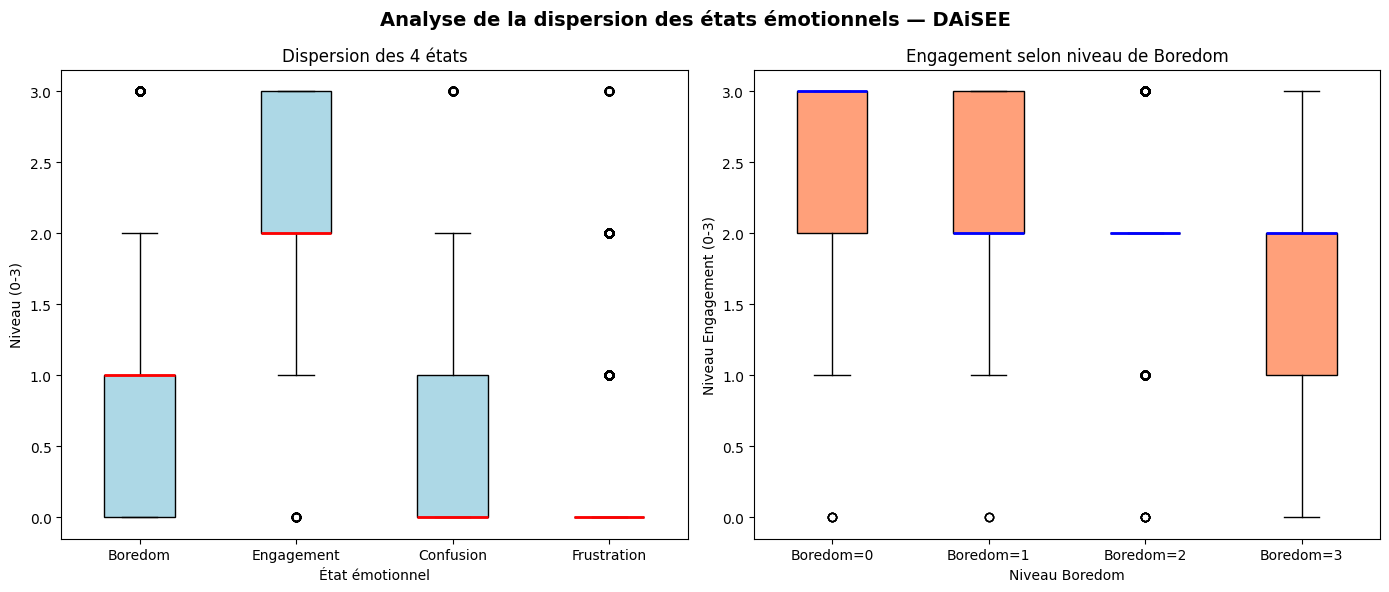

Boxplots sauvegardés !


In [16]:
# ============================================
# BOXPLOTS — DISPERSION DES 4 ÉTATS
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Analyse de la dispersion des états émotionnels — DAiSEE', 
             fontsize=14, fontweight='bold')

# Boxplot 1 — Les 4 états côte à côte
axes[0].boxplot(
    [train['Boredom'], train['Engagement'], 
     train['Confusion'], train['Frustration']],
    labels=['Boredom', 'Engagement', 'Confusion', 'Frustration'],
    patch_artist=True,
    boxprops=dict(facecolor='lightblue'),
    medianprops=dict(color='red', linewidth=2)
)
axes[0].set_title('Dispersion des 4 états', fontsize=12)
axes[0].set_ylabel('Niveau (0-3)')
axes[0].set_xlabel('État émotionnel')

# Boxplot 2 — Engagement par niveau de Boredom
boredom_groups = [
    train[train['Boredom'] == 0]['Engagement'],
    train[train['Boredom'] == 1]['Engagement'],
    train[train['Boredom'] == 2]['Engagement'],
    train[train['Boredom'] == 3]['Engagement']
]
axes[1].boxplot(
    boredom_groups,
    labels=['Boredom=0', 'Boredom=1', 'Boredom=2', 'Boredom=3'],
    patch_artist=True,
    boxprops=dict(facecolor='lightsalmon'),
    medianprops=dict(color='blue', linewidth=2)
)
axes[1].set_title('Engagement selon niveau de Boredom', fontsize=12)
axes[1].set_ylabel('Niveau Engagement (0-3)')
axes[1].set_xlabel('Niveau Boredom')

plt.tight_layout()
plt.savefig('../data/boxplots_etats.png', dpi=150)
plt.show()
print("Boxplots sauvegardés !")

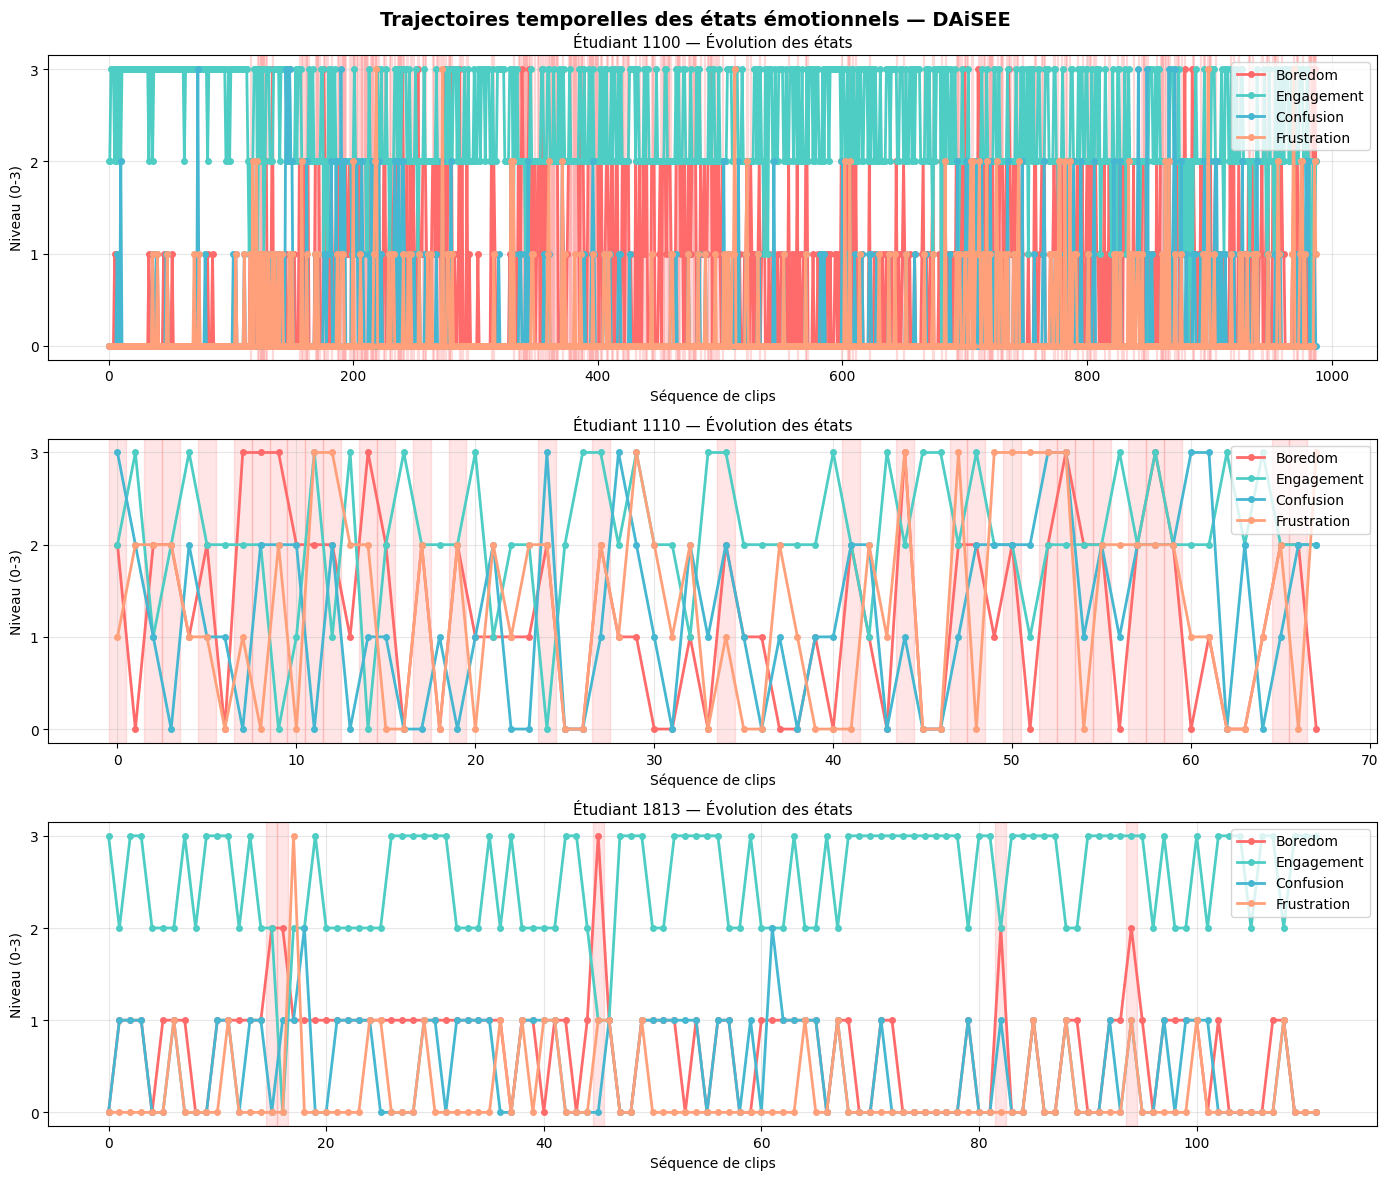

Trajectoires temporelles sauvegardées !


In [18]:
# ============================================
# TRAJECTOIRES TEMPORELLES
# ============================================

# Corriger les colonnes d'abord
train_sorted = train.sort_values('ClipID').reset_index(drop=True)
train_sorted.columns = train_sorted.columns.str.strip()

# Redéfinir etats
etats = ['Boredom', 'Engagement', 'Confusion', 'Frustration']

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle('Trajectoires temporelles des états émotionnels — DAiSEE', 
             fontsize=14, fontweight='bold')

# Extraire l'ID étudiant depuis le ClipID
train_sorted['StudentID'] = train_sorted['ClipID'].str[:4]

# Prendre 3 étudiants différents
etudiants = train_sorted['StudentID'].unique()[:3]
couleurs = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

for idx, etudiant in enumerate(etudiants):
    ax = axes[idx]
    data_etudiant = train_sorted[train_sorted['StudentID'] == etudiant].reset_index(drop=True)
    
    for etat, couleur in zip(etats, couleurs):
        ax.plot(data_etudiant.index, 
                data_etudiant[etat], 
                label=etat, 
                color=couleur,
                linewidth=2,
                marker='o',
                markersize=4)
    
    ax.set_title(f'Étudiant {etudiant} — Évolution des états', fontsize=11)
    ax.set_xlabel('Séquence de clips')
    ax.set_ylabel('Niveau (0-3)')
    ax.set_yticks([0, 1, 2, 3])
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    
    # Marquer les zones critiques en rouge
    for i in range(len(data_etudiant)):
        if data_etudiant.iloc[i]['Boredom'] >= 2:
            ax.axvspan(i-0.5, i+0.5, alpha=0.1, color='red')

plt.tight_layout()
plt.savefig('../data/trajectoires_temporelles.png', dpi=150)
plt.show()
print("Trajectoires temporelles sauvegardées !")